In [11]:
# libraries
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

Homework 2, problem 2, part c

In [12]:
# variables
V_0 = 16.13      
g = 1 # constant
E_N = 0

In [13]:
def B(V, Mg):
    return 1 / (1 + (Mg / 3.57) * np.exp(-V / V_0))

def IN(V, Mg):
    return g * B(V, Mg) * (V - E_N)

def dIN_dV(V, Mg):
    b = B(V, Mg)
    return g * b * (1 + V * (1 - b) / V_0)

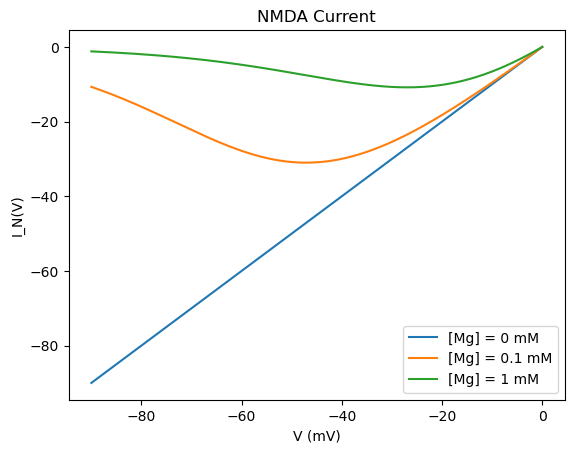

Mg = 0.1 mM: slope vanishes at V = -47.130 mV
Mg = 1 mM: slope vanishes at V = -26.957 mV


In [17]:
voltage_vals = np.linspace(-90, 0, 1000)
Mg_vals = [0, 0.1, 1] # magnesium

# Plot IN(V)
for Mg in Mg_vals:
    plt.plot(voltage_vals, IN(voltage_vals, Mg), label=f'[Mg] = {Mg} mM')

plt.xlabel('V (mV)')
plt.ylabel('I_N(V)')
plt.title('NMDA Current')
plt.legend()
plt.show()

# find voltage where slope = 0
for Mg in [0.1, 1]:
    dI = dIN_dV(voltage_vals, Mg) # sign change

    for i in range(len(voltage_vals) - 1):
        if dI[i] * dI[i+1] < 0:
            V_zero = brentq(
                lambda x: dIN_dV(x, Mg),
                voltage_vals[i],
                voltage_vals[i+1]
            )
            print(f'Mg = {Mg} mM: slope vanishes at V = {V_zero:.3f} mV')